# Experimentos con MNIST: mezclar, tamaño de lote y lo que `Flatten` no ve

El notebook anterior entrenó un clasificador con los valores del curso: lotes de 64, mezclados, imágenes aplanadas. Aquí cambiamos esas decisiones una por una para ver qué pasa:

- **Mezclar**: ¿qué pasa si el entrenamiento no se mezcla? ¿Y si además viene ordenado por dígito?
- **Tamaño del lote**: lotes de 16, 64 y 512. ¿Cuál entrena más rápido? ¿Cuál llega más lejos?
- **Aplanar**: `Flatten` convierte la imagen en una fila de 784 números. ¿Le importa a la red en qué orden van los píxeles?

Cada experimento entrena varias redes, así que precargamos MNIST en memoria (`00-datos/01_transforms_dataset_y_dataloader`, sección 9). Todo el notebook tarda alrededor de un minuto y medio en una CPU.

**Contenido**

1. Preparación
2. ¿Hace falta mezclar?
3. El tamaño del lote
4. Lo que `Flatten` no ve
5. Resumen y ejercicios

## 1. Preparación

`entrenar` recibe los datos y las decisiones que vamos a variar, y devuelve el modelo y una historia de la exactitud de prueba, medida cada cierta cantidad de lotes.

In [1]:
import time

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)


def precargar(entrenamiento):
    datos = datasets.MNIST(root="../data", train=entrenamiento, download=True)
    imagenes = ((datos.data.float() / 255 - 0.1307) / 0.3081).unsqueeze(1)
    return imagenes, datos.targets


X_entrenamiento, y_entrenamiento = precargar(True)
X_prueba, y_prueba = precargar(False)


def nueva_red():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


def exactitud(modelo, X=X_prueba, y=y_prueba):
    modelo.eval()
    with torch.no_grad():
        return (modelo(X).argmax(dim=1) == y).float().mean().item()


def entrenar(X, y, batch_size=64, shuffle=True, lr=0.001, epocas=1, medir_cada=None):
    torch.manual_seed(0)
    modelo = nueva_red()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    cargador = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(1))
    historia = {"lote": [0], "exactitud": [exactitud(modelo)], "segundos": [0.0]}
    inicio, lotes = time.perf_counter(), 0
    for epoca in range(epocas):
        modelo.train()
        for xb, yb in cargador:
            optimizador.zero_grad()
            criterio(modelo(xb), yb).backward()
            optimizador.step()
            lotes += 1
            if medir_cada and lotes % medir_cada == 0:
                historia["lote"].append(lotes)
                historia["exactitud"].append(exactitud(modelo))
                historia["segundos"].append(time.perf_counter() - inicio)
                modelo.train()
        if not medir_cada:                                 # sin medir_cada, se mide al final de cada época
            segundos = time.perf_counter() - inicio
            historia["lote"].append(lotes)
            historia["exactitud"].append(exactitud(modelo))
            historia["segundos"].append(segundos)
            inicio = time.perf_counter() - segundos       # el tiempo de medir no cuenta como entrenamiento
    return modelo, historia


print("entrenamiento:", tuple(X_entrenamiento.shape), "  prueba:", tuple(X_prueba.shape))

entrenamiento: (60000, 1, 28, 28)   prueba: (10000, 1, 28, 28)


## 2. ¿Hace falta mezclar?

Tres entrenamientos de una época, iguales salvo por el orden en que llegan los datos:

- **mezclado**: `shuffle=True`, como en el curso;
- **tal como viene**: `shuffle=False`, en el orden del archivo de MNIST;
- **ordenado por dígito**: `shuffle=False`, con los datos ordenados primero todos los 0, después todos los 1, y así hasta el 9.

La tercera variante no es un caso raro: muchos conjuntos de datos se guardan agrupados por clase, por ejemplo una carpeta de imágenes por categoría.

In [2]:
orden = torch.argsort(y_entrenamiento, stable=True)
X_ordenado, y_ordenado = X_entrenamiento[orden], y_entrenamiento[orden]
print("primeras etiquetas tal como viene :", y_entrenamiento[:15].tolist())
print("primeras etiquetas ordenado       :", y_ordenado[:15].tolist())

variantes = {
    "mezclado": (X_entrenamiento, y_entrenamiento, True),
    "tal como viene": (X_entrenamiento, y_entrenamiento, False),
    "ordenado por dígito": (X_ordenado, y_ordenado, False),
}
resultados_orden = {}
for nombre, (X, y, mezclar) in variantes.items():
    resultados_orden[nombre] = entrenar(X, y, shuffle=mezclar, medir_cada=20)
    print(f"{nombre:20s} exactitud de prueba al final de la época: {resultados_orden[nombre][1]['exactitud'][-1]:.1%}")

primeras etiquetas tal como viene : [5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1]
primeras etiquetas ordenado       : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


mezclado             exactitud de prueba al final de la época: 95.8%


tal como viene       exactitud de prueba al final de la época: 95.6%


ordenado por dígito  exactitud de prueba al final de la época: 10.4%


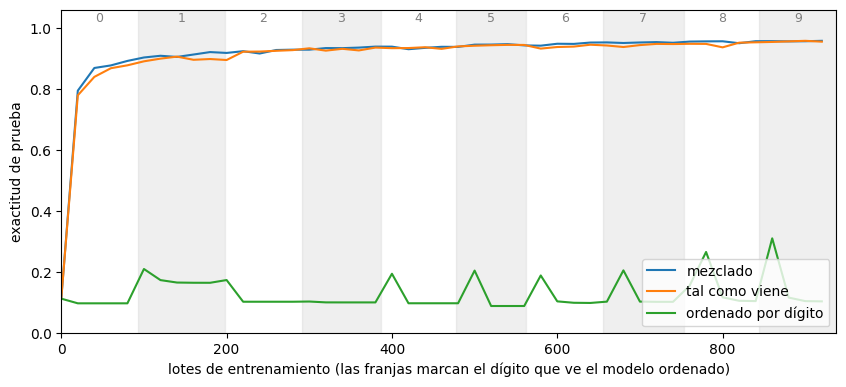

In [3]:
fig, eje = plt.subplots(figsize=(10, 4.2))

# franjas: qué dígito está viendo el modelo ordenado en cada tramo de la época
inicio_digito = 0
for d in range(10):
    lotes_d = (y_ordenado == d).sum().item() / 64
    eje.axvspan(inicio_digito, inicio_digito + lotes_d, color="gray" if d % 2 else "white", alpha=0.12)
    eje.text(inicio_digito + lotes_d / 2, 1.02, str(d), ha="center", fontsize=9, color="gray")
    inicio_digito += lotes_d

for nombre, (_, historia) in resultados_orden.items():
    eje.plot(historia["lote"], historia["exactitud"], label=nombre)
eje.set_xlabel("lotes de entrenamiento (las franjas marcan el dígito que ve el modelo ordenado)")
eje.set_ylabel("exactitud de prueba")
eje.set_ylim(0, 1.06)
eje.set_xlim(0, len(y_ordenado) / 64)
eje.legend(loc="lower right")
plt.show()

Mezclado y tal como viene terminan casi iguales, 95.8% y 95.6%, porque MNIST ya viene mezclado en el archivo. El ordenado por dígito es un desastre: pasa toda la época cerca del 10%.

La razón se ve en las franjas. Mientras el modelo ve solo ceros, cada paso lo empuja a contestar "0", y en pocos lotes contesta "0" a todo. Su exactitud es entonces la fracción de ceros en la prueba: alrededor de 10%. Cuando empiezan los unos, aprende a contestar "1" a todo, y olvida los ceros. Las subidas cortas, justo después de algunos cambios de dígito, son los momentos en que todavía reconoce el dígito anterior y ya empezó a reconocer el nuevo; a los pocos lotes, el nuevo borra al anterior. Nada en el entrenamiento le recuerda los dígitos que ya pasaron. Este fenómeno se llama **olvido catastrófico**.

Al terminar la época, ¿qué contesta el modelo ordenado? Contamos cuántas veces predice cada dígito en las 10.000 imágenes de prueba:

In [4]:
modelo_ordenado = resultados_orden["ordenado por dígito"][0]
with torch.no_grad():
    predicciones = modelo_ordenado(X_prueba).argmax(dim=1)
for d, n in enumerate(torch.bincount(predicciones, minlength=10).tolist()):
    print(f"predice {d}: {n:5d} veces")

predice 0:     0 veces
predice 1:     0 veces
predice 2:     1 veces
predice 3:    58 veces
predice 4:     0 veces
predice 5:    17 veces
predice 6:    23 veces
predice 7:     0 veces
predice 8:     0 veces
predice 9:  9901 veces


Contesta "9" en el 99% de las imágenes: el último dígito que vio. Al mezclar, en cambio, cada lote trae unos seis ejemplos de cada dígito, y el gradiente de cada paso empuja hacia un modelo que los distinga a todos a la vez.

## 3. El tamaño del lote

Entrenamos tres épocas con lotes de 16, 64 y 512, todos con `Adam` y `lr=0.001`, midiendo la exactitud de prueba al final de cada época y el tiempo de entrenamiento.

In [5]:
resultados_lote = {}
for tamano in [16, 64, 512]:
    _, historia = entrenar(X_entrenamiento, y_entrenamiento, batch_size=tamano, epocas=3)
    resultados_lote[f"lote de {tamano}"] = historia
    pasos_por_epoca = historia["lote"][1]
    print(f"lote de {tamano:3d}: {pasos_por_epoca:4d} pasos por época   {historia['segundos'][-1]:5.1f} s en total   "
          f"exactitud por época: {', '.join(f'{a:.1%}' for a in historia['exactitud'][1:])}")

lote de  16: 3750 pasos por época    23.3 s en total   exactitud por época: 96.5%, 96.8%, 97.1%


lote de  64:  938 pasos por época     8.5 s en total   exactitud por época: 95.6%, 96.6%, 97.4%


lote de 512:  118 pasos por época     4.3 s en total   exactitud por época: 93.0%, 94.9%, 96.0%


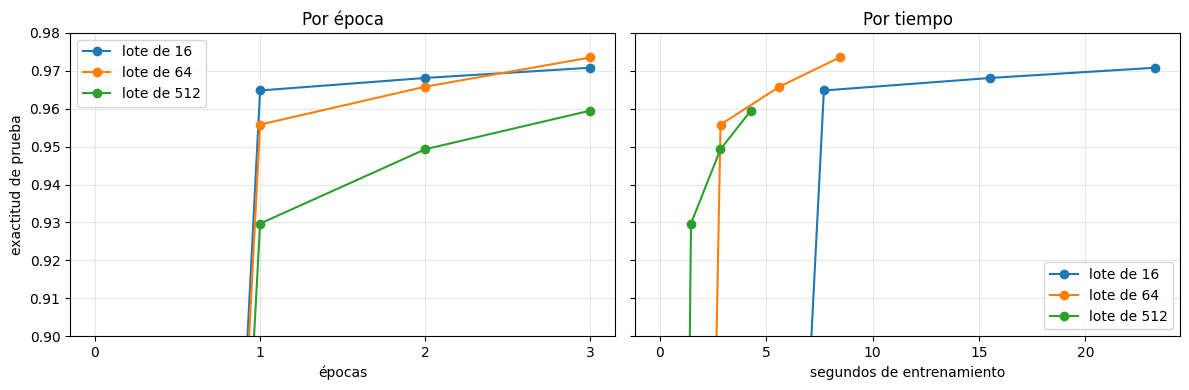

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for nombre, historia in resultados_lote.items():
    ejes[0].plot(range(4), historia["exactitud"], marker="o", label=nombre)
    ejes[1].plot(historia["segundos"], historia["exactitud"], marker="o", label=nombre)
ejes[0].set_xlabel("épocas")
ejes[0].set_xticks(range(4))
ejes[1].set_xlabel("segundos de entrenamiento")
ejes[0].set_ylabel("exactitud de prueba")
for eje in ejes:
    eje.set_ylim(0.9, 0.98)
    eje.grid(alpha=0.3)
    eje.legend()
ejes[0].set_title("Por época")
ejes[1].set_title("Por tiempo")
plt.tight_layout()
plt.show()

**Por época** (izquierda), los lotes chicos van adelante al principio: después de una época, el lote de 16 acierta 96.5%, el de 64 95.6% y el de 512 93.0%. La razón es el número de pasos: con lotes de 16 el modelo se actualiza 3.750 veces por época, con lotes de 512 solo 118. Pero el lote de 16 avanza poco después de la primera época, y en la tercera el de 64 lo pasa, 97.4% contra 97.1%. Con lotes tan chicos el gradiente de cada paso es más ruidoso, y con la misma tasa ese ruido hace más difícil afinar (`02-descenso-de-gradiente/02_sgd_y_minibatches` en el módulo 1).

**Por tiempo** (derecha), el orden cambia. El lote de 16 es el más lento: tarda cerca de tres veces más que el de 64 por época. Cada paso tiene un costo fijo (llamar a las capas, calcular la pérdida, actualizar los pesos) que no depende del tamaño del lote, y con lotes de 16 ese costo se paga 3.750 veces. El de 512 es el que recorre los datos más rápido, pero avanza poco por época. En este computador, el lote de 64 es el mejor equilibrio entre las dos cosas, y por eso es un valor por defecto tan común.

En una GPU la cuenta es otra: procesar 512 imágenes cuesta poco más que procesar 64, porque se hacen en paralelo, y los lotes grandes ganan más tiempo que en una CPU.

Con lotes de 512 hay 8 veces menos pasos que con 64. Una forma de compensar es dar pasos más largos. Probamos subir la tasa de aprendizaje a 0.004:

In [7]:
_, historia = entrenar(X_entrenamiento, y_entrenamiento, batch_size=512, lr=0.004, epocas=3)
resultados_lote["lote de 512, lr = 0.004"] = historia
for nombre in ["lote de 64", "lote de 512", "lote de 512, lr = 0.004"]:
    h = resultados_lote[nombre]
    print(f"{nombre:24s} exactitud tras 3 épocas {h['exactitud'][-1]:.1%}   en {h['segundos'][-1]:4.1f} s")

lote de 64               exactitud tras 3 épocas 97.4%   en  8.5 s
lote de 512              exactitud tras 3 épocas 96.0%   en  4.3 s
lote de 512, lr = 0.004  exactitud tras 3 épocas 97.1%   en  3.9 s


Con la tasa cuatro veces mayor, el lote de 512 llega a 97.1%, cerca del 97.4% del lote de 64, en menos de la mitad del tiempo. Subir la tasa cuando se sube el lote es una regla práctica muy usada. Con lotes grandes el gradiente de cada paso tiene menos ruido, así que se puede confiar más en él y dar pasos más largos. No funciona sin límite: pasado cierto punto, la tasa es demasiado grande y el entrenamiento se desestabiliza (`02-entrenamiento/02_gradientes_y_optimizadores`, sección 8).

## 4. Lo que `Flatten` no ve

`Flatten` pone los 784 píxeles en fila, y la primera capa conecta cada uno con cada neurona. ¿Le importa a la red cuál píxel está al lado de cuál? Para averiguarlo, sorteamos un orden al azar de los 784 píxeles y lo aplicamos a **todas** las imágenes, de entrenamiento y de prueba. Es el mismo desorden para todas, así que no se pierde información: solo se reordena.

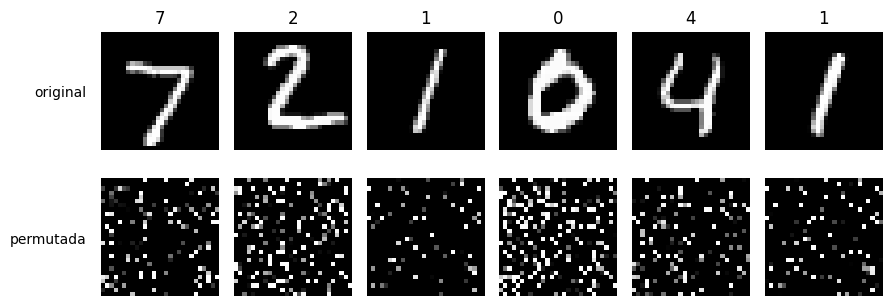

In [8]:
permutacion = torch.randperm(784, generator=torch.Generator().manual_seed(0))


def permutar(X):
    return X.flatten(1)[:, permutacion].reshape(-1, 1, 28, 28)


X_entrenamiento_p, X_prueba_p = permutar(X_entrenamiento), permutar(X_prueba)

fig, ejes = plt.subplots(2, 6, figsize=(9, 3.4))
for k in range(6):
    ejes[0, k].imshow(X_prueba[k, 0], cmap="gray")
    ejes[1, k].imshow(X_prueba_p[k, 0], cmap="gray")
    ejes[0, k].set_title(y_prueba[k].item())
for eje in ejes.flat:
    eje.axis("off")
ejes[0, 0].text(-4, 14, "original", ha="right", va="center")
ejes[1, 0].text(-4, 14, "permutada", ha="right", va="center")
plt.tight_layout()
plt.show()

Para una persona, las imágenes permutadas son ruido. Entrenamos la misma red tres épocas con cada versión:

In [9]:
modelo_original, h_original = entrenar(X_entrenamiento, y_entrenamiento, epocas=3)
modelo_permutado, h_permutado = entrenar(X_entrenamiento_p, y_entrenamiento, epocas=3)

print(f"imágenes originales: exactitud de prueba {exactitud(modelo_original):.2%}")
print(f"imágenes permutadas: exactitud de prueba {exactitud(modelo_permutado, X_prueba_p):.2%}")

imágenes originales: exactitud de prueba 97.35%
imágenes permutadas: exactitud de prueba 97.31%


97.35% contra 97.31%: la red aprende igual de bien con las imágenes desordenadas. La diferencia son 4 imágenes de 10.000.

Se puede ir más lejos y mostrar que, para esta red, los dos problemas son **el mismo**. La primera capa calcula $W x$, una suma de las columnas de $W$ pesadas por los píxeles. Si los píxeles se reordenan, basta reordenar las columnas de $W$ de la misma forma para obtener exactamente el mismo resultado. Tomamos el modelo entrenado con las imágenes originales, le reordenamos las columnas de la primera capa, y lo evaluamos con las imágenes permutadas:

In [10]:
trasplantado = nueva_red()
trasplantado.load_state_dict(modelo_original.state_dict())
with torch.no_grad():
    trasplantado[1].weight.copy_(modelo_original[1].weight[:, permutacion])

print(f"modelo original con imágenes originales     : {exactitud(modelo_original):.2%}")
print(f"modelo reordenado con imágenes permutadas   : {exactitud(trasplantado, X_prueba_p):.2%}")

with torch.no_grad():
    iguales = (modelo_original(X_prueba).argmax(dim=1) == trasplantado(X_prueba_p).argmax(dim=1)).float().mean()
print(f"imágenes de prueba con la misma predicción     : {iguales:.2%}")

modelo original con imágenes originales     : 97.35%
modelo reordenado con imágenes permutadas   : 97.35%
imágenes de prueba con la misma predicción     : 100.00%


Da exactamente la misma exactitud, y la misma predicción en cada una de las 10.000 imágenes. Para una red densa, el orden de los píxeles es una etiqueta arbitraria: no sabe que el píxel 300 está al lado del 301, ni que hay un "arriba" y un "abajo". Todo lo que sabe de la forma de los dígitos lo tuvo que deducir de los datos, píxel por píxel.

Es una limitación, y explica algo que se ve en la práctica: si un dígito aparece corrido unos píxeles hacia un lado, los píxeles que antes tenían tinta ahora están vacíos y viceversa, y la red densa lo ve como una imagen muy distinta. Las **redes convolucionales**, que vienen en los módulos siguientes, parten de lo contrario: los píxeles vecinos están relacionados, y un mismo trazo significa lo mismo en cualquier parte de la imagen.

## 5. Resumen

- **Mezclar el entrenamiento es necesario** cuando los datos vienen agrupados por clase. Con MNIST ordenado por dígito, el modelo aprende cada dígito y lo olvida al pasar al siguiente, y termina contestando casi siempre el último que vio. MNIST tal como viene ya está mezclado, así que `shuffle=False` cambia poco ahí, pero mezclar es la opción segura.
- **El tamaño del lote** decide cuántos pasos hay por época. Lotes chicos dan más pasos y más progreso por época, pero cada época cuesta más tiempo. Lotes grandes recorren los datos más rápido, pero con la misma tasa avanzan menos por época; subir la tasa compensa en parte.
- **Una red densa no sabe de vecindad**: con los píxeles permutados aprende igual de bien, porque para ella los dos problemas son el mismo, salvo por el orden de las columnas de la primera capa. Esa es la limitación que resuelven las redes convolucionales.

## Ejercicios

1. Entrena el modelo ordenado por dígito durante tres épocas. ¿Mejora de una época a otra? ¿Con qué dígito termina cada época?
2. Ordena los datos de forma intercalada: un 0, un 1, un 2, ..., un 9, un 0, un 1, y así. ¿Hace falta mezclar en ese caso? ¿Por qué?
3. Entrena con lotes de 1 durante 3.000 pasos. ¿Cuánto tarda y a qué exactitud llega? ¿Por qué cada paso es tan ruidoso?
4. Con lotes de 512, prueba `lr` de 0.002, 0.004 y 0.008. ¿Alguna tasa alcanza a los lotes de 64 en exactitud por época?
5. Entrena con imágenes permutadas, pero evalúa con una permutación **distinta** en la prueba. ¿Qué exactitud da? ¿Por qué?
6. Corre las imágenes de prueba 3 píxeles a la derecha con `torch.roll(X_prueba, shifts=3, dims=3)` y evalúa el modelo original. ¿Cuánta exactitud pierde? ¿Y con 1 y 5 píxeles?